In [1]:
import scanpy as sc
import pandas as pd
import hdf5plugin
import seaborn as sns
from pathlib import Path
import matplotlib.pyplot as plt
from parameters import pc_parameters
from scipy.sparse import csr_matrix
import warnings
warnings.filterwarnings("ignore")
from scvi.external import SysVI

In [2]:

base = "defaria"

merged = sc.read_h5ad("/home/sofia/Projects/etmr/defaria/snRNA/data/processed/merged/combined_GSM8058165_KK23-H-512.h5ad")

In [3]:
merged

AnnData object with n_obs × n_vars = 45041 × 15196
    obs: 'sample_origin', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'pct_counts_ribo', 'species'
    layers: 'counts'

In [4]:
merged.X[5:].toarray()

array([[11.,  0.,  0., ...,  0.,  0.,  0.],
       [ 7.,  0.,  0., ...,  0.,  0.,  0.],
       [47.,  0.,  0., ...,  0.,  0.,  0.],
       ...,
       [ 0.,  0.,  0., ...,  0.,  0.,  0.],
       [ 0.,  0.,  0., ...,  0.,  0.,  0.],
       [ 0.,  0.,  0., ...,  0.,  0.,  0.]], shape=(45036, 15196))

In [5]:
merged.layers["counts"][5:].toarray()

array([[11.,  0.,  0., ...,  0.,  0.,  0.],
       [ 7.,  0.,  0., ...,  0.,  0.,  0.],
       [47.,  0.,  0., ...,  0.,  0.,  0.],
       ...,
       [ 0.,  0.,  0., ...,  0.,  0.,  0.],
       [ 0.,  0.,  0., ...,  0.,  0.,  0.],
       [ 0.,  0.,  0., ...,  0.,  0.,  0.]], shape=(45036, 15196))

In [6]:
merged.obs

,sample_origin,n_genes_by_counts,total_counts,total_counts_mt,pct_counts_mt,total_counts_ribo,pct_counts_ribo,species
12_KO1_SP_AAACCCAAGACGCAGT-1-KO,12_KO1_SP,4438,14857.0,67.0,0.450966,609.0,4.099078,humanized
12_KO1_SP_AAACCCAAGGTCACCC-1-KO,12_KO1_SP,4189,12223.0,47.0,0.384521,201.0,1.644441,humanized
12_KO1_SP_AAACCCAAGGTCTACT-1-KO,12_KO1_SP,6109,26033.0,51.0,0.195905,515.0,1.978258,humanized
12_KO1_SP_AAACCCACAAAGACGC-1-KO,12_KO1_SP,5792,23484.0,76.0,0.323625,1724.0,7.341168,humanized
12_KO1_SP_AAACCCACAATTCTTC-1-KO,12_KO1_SP,5107,19465.0,79.0,0.405857,476.0,2.445415,humanized
...,...,...,...,...,...,...,...,...
TTTGCCCGTGCCCGATATGTTGAC-1,GSM8058165_KK23-H-512,457,514.0,13.0,2.529183,0.0,0.000000,tumor
TTTGCGCAGGGTGGGAATGTTGAC-1,GSM8058165_KK23-H-512,1472,1822.0,5.0,0.274424,0.0,0.000000,tumor
TTTGCTGAGAGGTTTAATGTTGAC-1,GSM8058165_KK23-H-512,286,306.0,2.0,0.653595,0.0,0.000000,tumor
TTTGCTGAGGGCACTAATGTTGAC-1,GSM8058165_KK23-H-512,295,335.0,15.0,4.477612,0.0,0.000000,tumor


In [7]:
sc.pp.highly_variable_genes(merged, flavor='seurat_v3', layer="counts", batch_key="species", n_top_genes=2000) #Calculate highly variable genes, using the unnormalized counts layer
sc.pp.normalize_total(merged, target_sum=1e4) #library size normalization
sc.pp.log1p(merged)
merged.raw = merged.copy() 

# sc.pp.regress_out(merged, ["total_counts", "pct_counts_mt"], n_jobs=1)

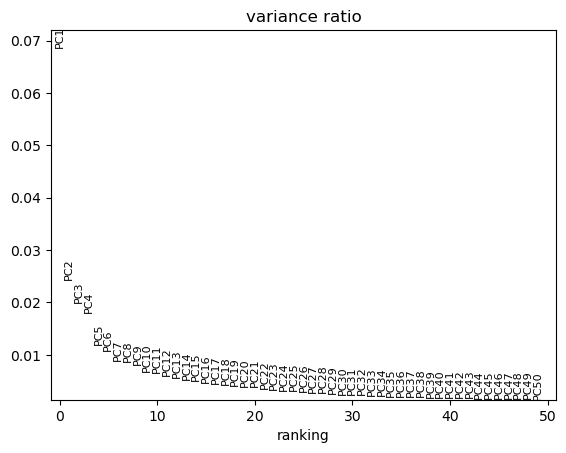

In [ ]:
merged.layers["scale.data"] = merged.X.copy() 
# merged.layers["X"] = merged.X.copy() 
sc.pp.scale(merged, layer="scale.data")

sc.pp.pca(merged, use_highly_variable=True,  n_comps=50, layer="scale.data")
sc.pl.pca_variance_ratio(merged, n_pcs=50, log=False) #plot the variance explained by each of the first 50 PCs, to help determine how many PCs to use for downstream analyses


In [12]:
print(merged.X[5:].toarray())
print(merged.layers["X"][5:].toarray())
print(merged.layers["scale.data"][5:])

[[2.07612363 0.         0.         ... 0.         0.         0.        ]
 [1.87135506 0.         0.         ... 0.         0.         0.        ]
 [3.46837791 0.         0.         ... 0.         0.         0.        ]
 ...
 [0.         0.         0.         ... 0.         0.         0.        ]
 [0.         0.         0.         ... 0.         0.         0.        ]
 [0.         0.         0.         ... 0.         0.         0.        ]]
[[2.07612363 0.         0.         ... 0.         0.         0.        ]
 [1.87135506 0.         0.         ... 0.         0.         0.        ]
 [3.46837791 0.         0.         ... 0.         0.         0.        ]
 ...
 [0.         0.         0.         ... 0.         0.         0.        ]
 [0.         0.         0.         ... 0.         0.         0.        ]
 [0.         0.         0.         ... 0.         0.         0.        ]]
[[ 1.44348561 -0.012924   -0.61728679 ... -0.45261643 -0.35919599
  -0.03969922]
 [ 1.21971876 -0.012924   -0.61

In [14]:
sc.external.pp.harmony_integrate(merged, key="sample_origin")

2026-03-02 18:02:12,765 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...
2026-03-02 18:02:26,526 - harmonypy - INFO - sklearn.KMeans initialization complete.
2026-03-02 18:02:26,878 - harmonypy - INFO - Iteration 1 of 10
2026-03-02 18:02:54,256 - harmonypy - INFO - Iteration 2 of 10
2026-03-02 18:03:21,406 - harmonypy - INFO - Iteration 3 of 10
2026-03-02 18:03:45,943 - harmonypy - INFO - Converged after 3 iterations


In [15]:
sc.pp.neighbors(
                merged,
                n_neighbors=pc_parameters["n_neighbors"],
                n_pcs=pc_parameters["n_pcs"],
                use_rep="X_pca_harmony"
            ) #compute the neighborhood graph of cells using the specified number of neighbors and PCs, which will be used for UMAP and Leiden clustering

            # UMAP
sc.tl.umap(
                merged
            )

            # Leiden
sc.tl.leiden(
                merged,
                resolution=pc_parameters["leiden_resolution"]
            )




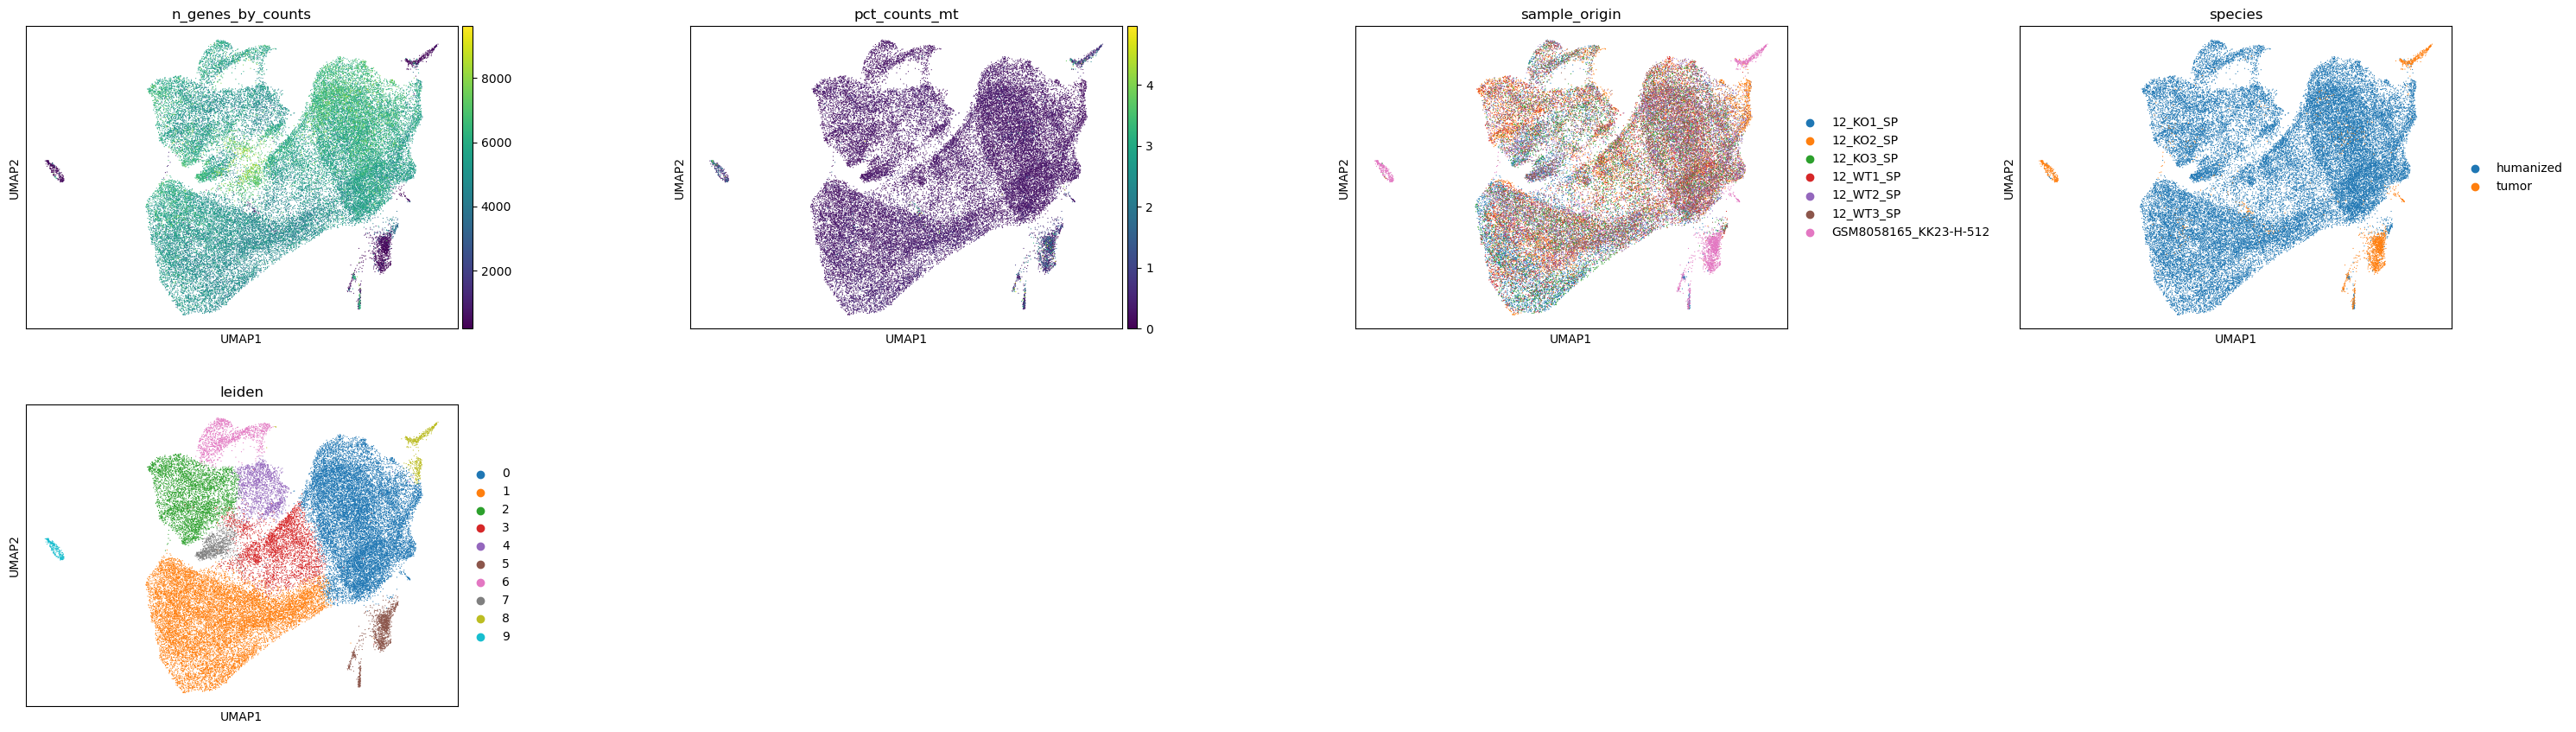

In [16]:
sc.pl.umap(merged, color=["n_genes_by_counts", "pct_counts_mt", "sample_origin", "species","leiden"], wspace=0.4)

In [18]:


df_counts = pd.crosstab(
    merged.obs["leiden"],
    merged.obs["sample_origin"]
)

df_counts

sample_origin,12_KO1_SP,12_KO2_SP,12_KO3_SP,12_WT1_SP,12_WT2_SP,12_WT3_SP,GSM8058165_KK23-H-512
leiden,,,,,,,
0,1549,2800,2908,2838,3689,3015,137
1,4141,1987,2335,1842,1894,1540,106
2,697,1231,633,638,718,593,40
3,502,861,744,553,450,443,5
4,268,317,364,201,224,339,7
5,113,13,29,33,14,25,1149
6,286,176,215,114,175,303,5
7,366,6,117,40,218,261,6
8,5,185,1,2,10,12,305


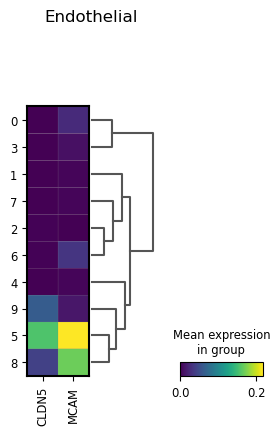

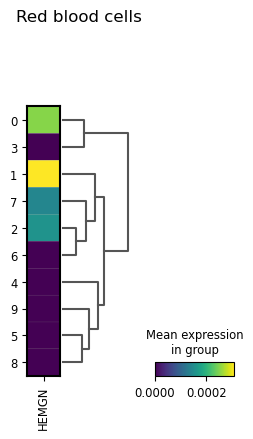

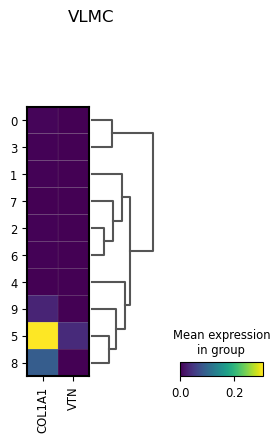

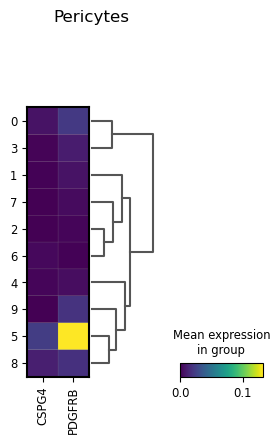

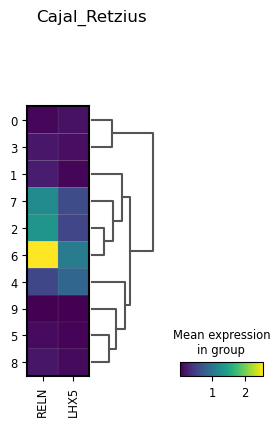

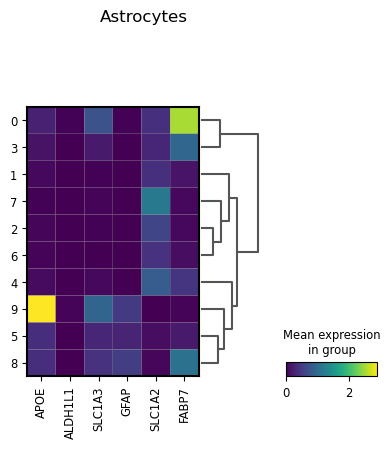

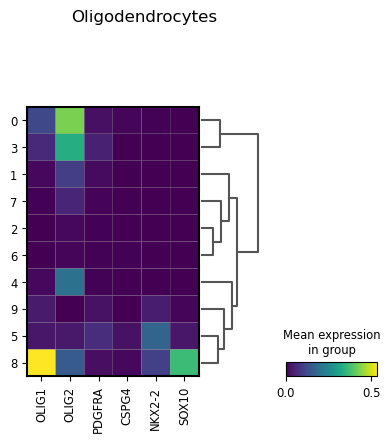

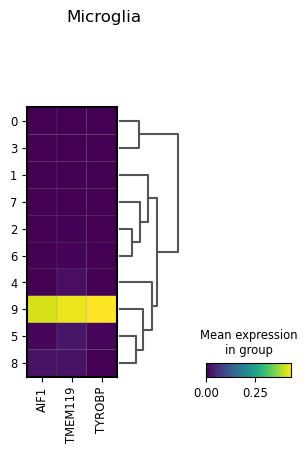

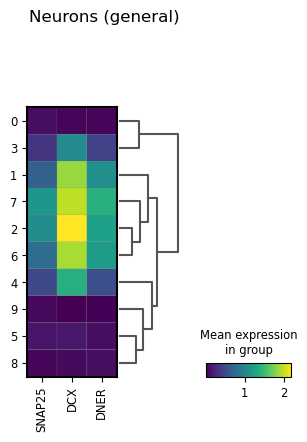

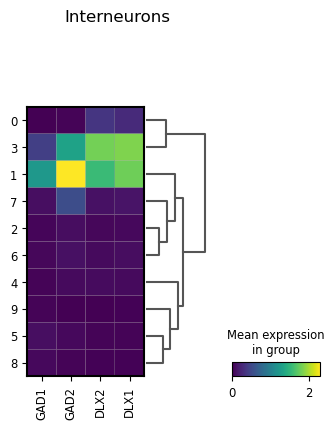

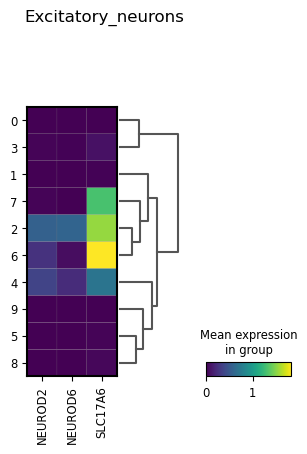

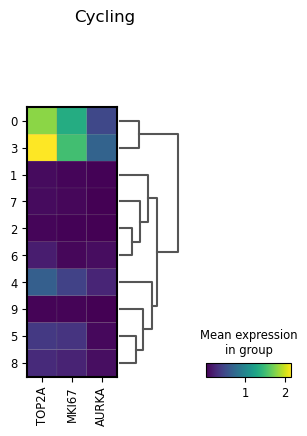

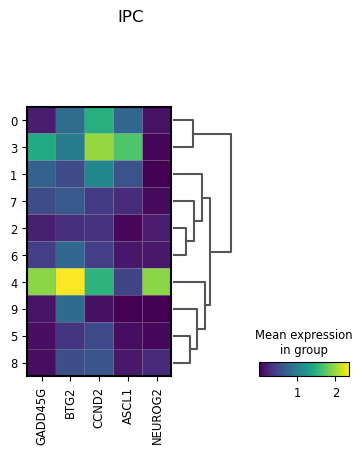

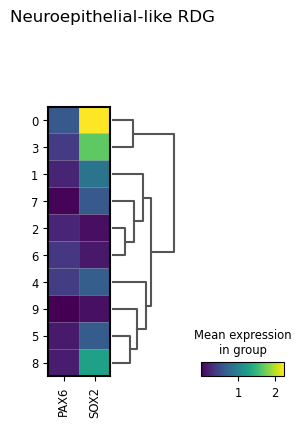

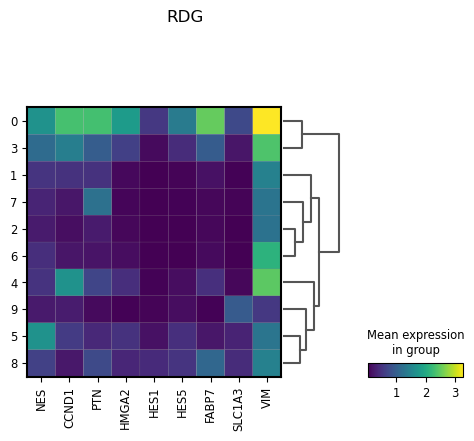

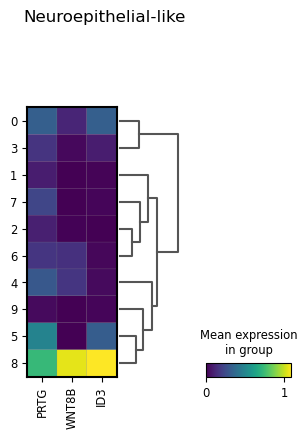

In [20]:
prov_ann = {
    "Endothelial": ["CLDN5", "MCAM"],
    "Red blood cells": ["HEMGN"],
    "VLMC": ["COL1A1", "VTN"],
    "Pericytes": ["CSPG4", "PDGFRB"],
    "Cajal_Retzius": ["RELN", "LHX5"],
    "Astrocytes": ["APOE", "ALDH1L1", "SLC1A3", "GFAP", "SLC1A2", "FABP7"],
    "Oligodendrocytes": ["OLIG1", "OLIG2", "PDGFRA", "CSPG4", "NKX2-2", "SOX10"],
    "Microglia": ["AIF1", "TMEM119", "TYROBP"],
    "Neurons (general)": ["SNAP25", "DCX", "DNER"],
    "Interneurons": ["GAD1", "GAD2", "DLX2", "DLX1"],
    "Excitatory_neurons": ["NEUROD2", "NEUROD6", "SLC17A6"],
    "Cycling": ["TOP2A", "MKI67", "AURKA"],
    "IPC": ["GADD45G", "BTG2", "CCND2", # general
         "ASCL1",                    # inhibitorias
         "NEUROG2"]  ,
    "Neuroepithelial-like RDG": ["PAX6", "SOX2"],
    "RDG": ["NES", "CCND1", "PTN", "HMGA2", "HES1", "HES5", "FABP7", "SLC1A3", "VIM"],
    "Neuroepithelial-like": ["PRTG", "WNT8B", "ID3"],
}
for name, gene in prov_ann.items(): 
    sc.pl.matrixplot(merged, gene, groupby="leiden", show=False, dendrogram=True, title=name)

In [ ]:
merged = merged.raw.to_adata()

In [ ]:
merged.obsm["X_pca"]

array([[ 10.821822  ,  -3.8458369 ,   8.5420065 , ...,  -0.82863915,
          2.4995136 ,  -1.0808042 ],
       [ 14.686009  ,   3.1389217 ,  -7.7690296 , ...,  -0.21826738,
          0.5826725 ,   0.04060465],
       [ 18.765045  ,   9.162699  ,  -9.731758  , ...,  -0.81838244,
         -0.584397  ,  -0.06668809],
       ...,
       [ -2.1291454 , -19.77288   ,  -8.966035  , ...,  -0.6713945 ,
          0.70033747,   0.12236661],
       [  0.6590941 , -32.46184   , -19.782976  , ...,   0.6335242 ,
          3.1228707 ,   1.4917527 ],
       [ -1.0656357 , -20.909552  ,  -8.081192  , ...,  -1.0275395 ,
          0.381823  ,   0.7408553 ]], shape=(45041, 50), dtype=float32)

In [ ]:
merged.obsm["X_pca_harmony"]

array([[ 9.27432627e+00, -5.03334193e+00,  5.25391990e+00, ...,
        -6.47308338e-01,  1.98016557e+00, -8.88571454e-01],
       [ 1.28940238e+01,  3.54235238e-01, -7.44310111e+00, ...,
         1.91410765e-02,  5.64287916e-01,  1.65515221e-01],
       [ 1.61917883e+01,  5.45613664e+00, -9.51381806e+00, ...,
        -1.23451435e+00,  7.22111871e-01, -9.25085103e-02],
       ...,
       [-8.28332015e+00, -7.02114862e-01, -5.07930552e+00, ...,
        -2.68906985e-01,  9.99831529e-02,  4.10477339e-03],
       [-5.01968928e+00, -1.03075001e+01, -1.35472754e+01, ...,
         1.65661114e+00,  5.48891694e+00, -4.37395166e-01],
       [-7.20382225e+00, -1.83985402e+00, -4.22601367e+00, ...,
        -6.30377105e-01, -2.19521927e-01,  6.21263568e-01]],
      shape=(45041, 50))

In [ ]:
merged.layers["scale.data"] = merged.X.copy() 
sc.pp.scale(merged, layer="scale.data")

INFO     The model has been initialized                                                                            


GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


Epoch 178/178: 100%|██████████| 178/178 [22:39<00:00,  7.57s/it, v_num=1, train_loss=-1.85e+4]

`Trainer.fit` stopped: `max_epochs=178` reached.


Epoch 178/178: 100%|██████████| 178/178 [22:39<00:00,  7.64s/it, v_num=1, train_loss=-1.85e+4]


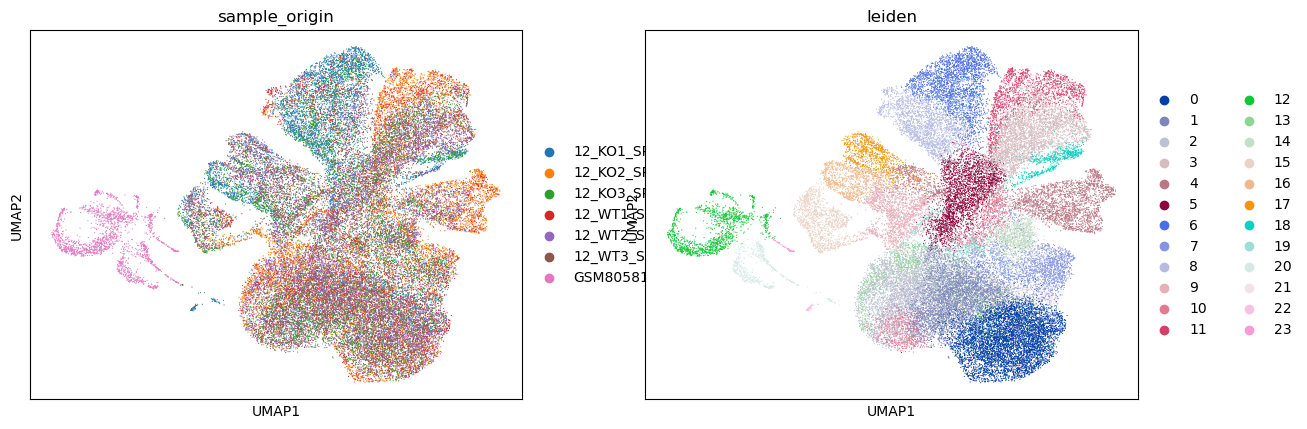

In [ ]:
SysVI.setup_anndata(
    adata=merged,
    batch_key="sample_origin"
)


model = SysVI(merged)
model.train()

embed = model.get_latent_representation(adata=merged)
embed = sc.AnnData(embed, obs=merged.obs)

sc.pp.neighbors(
                embed,
                n_neighbors=pc_parameters["n_neighbors"],
                n_pcs=pc_parameters["n_pcs"],)
sc.tl.umap(embed)
sc.tl.leiden(
                embed,
                resolution=pc_parameters["leiden_resolution"])

sc.pl.umap(embed, color=["sample_origin", "leiden"])

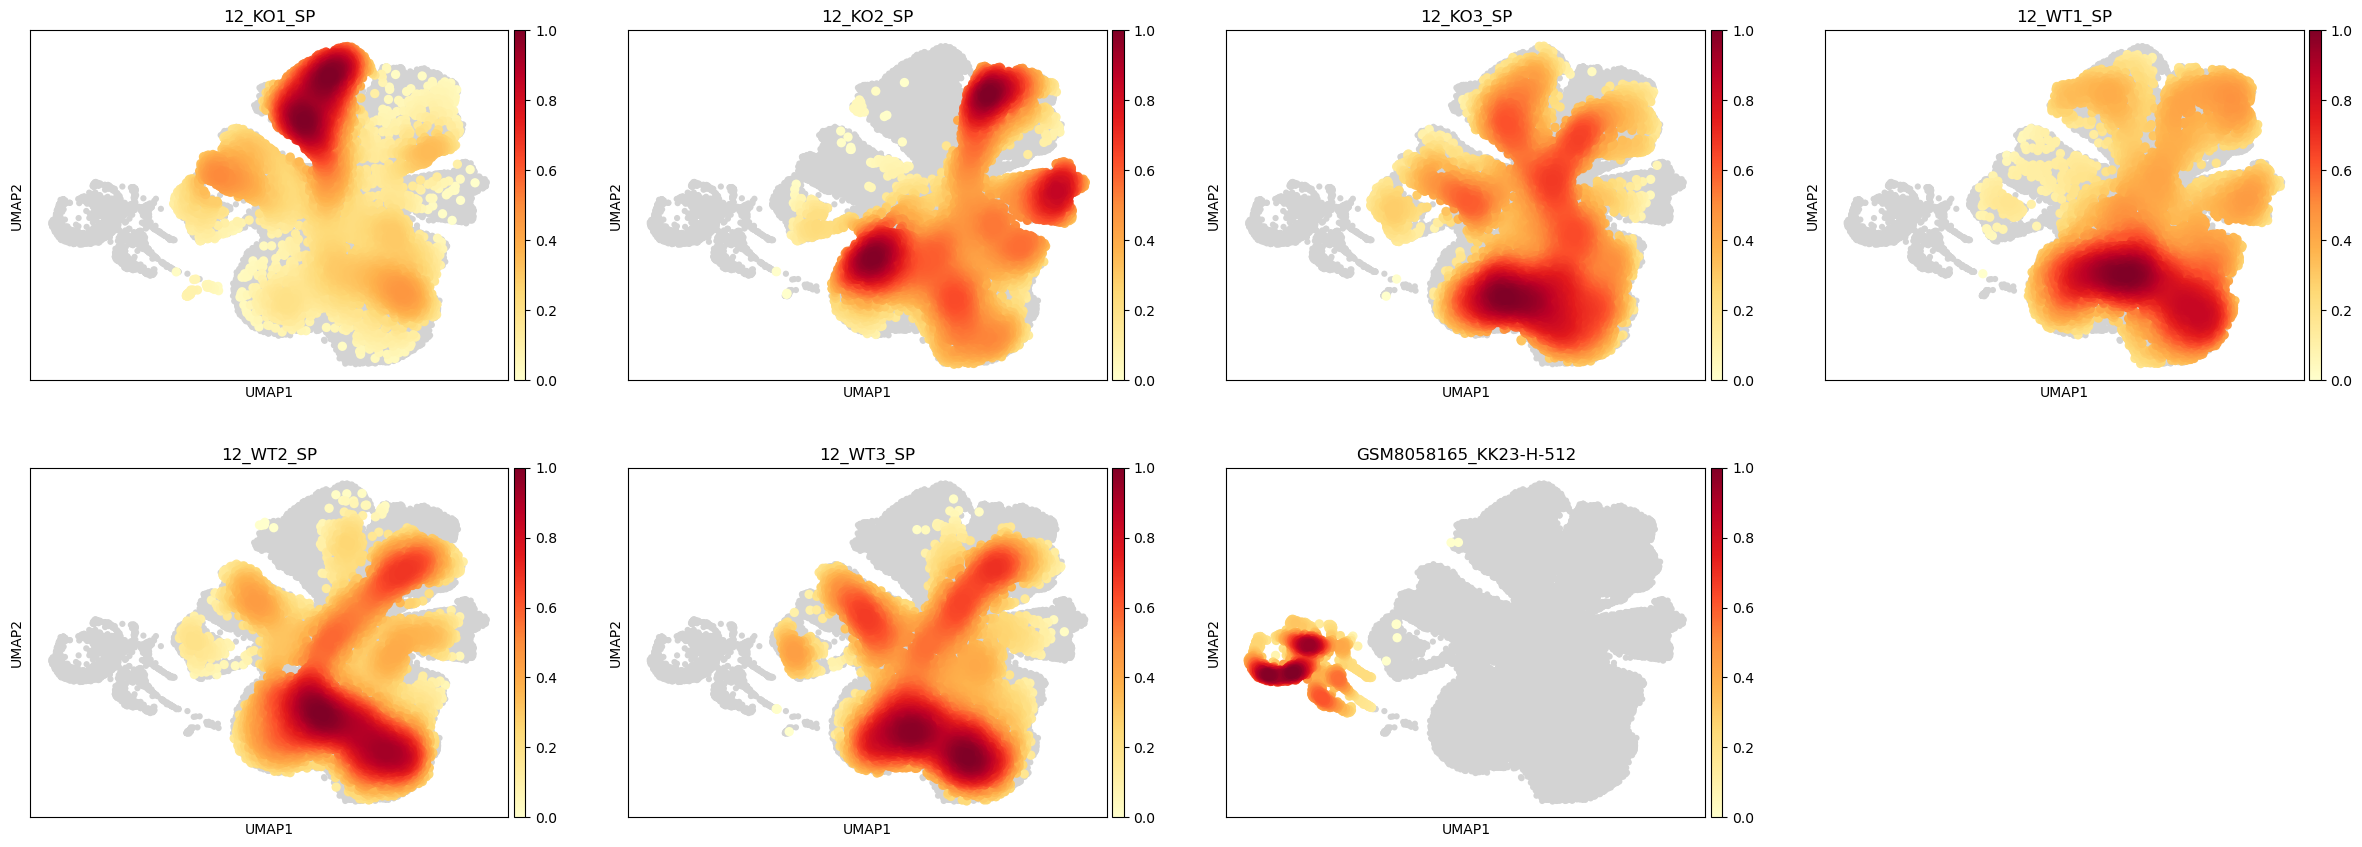

In [ ]:
sc.tl.embedding_density(embed, basis="umap", groupby="sample_origin")
sc.pl.embedding_density(embed, basis="umap", groupby="sample_origin")

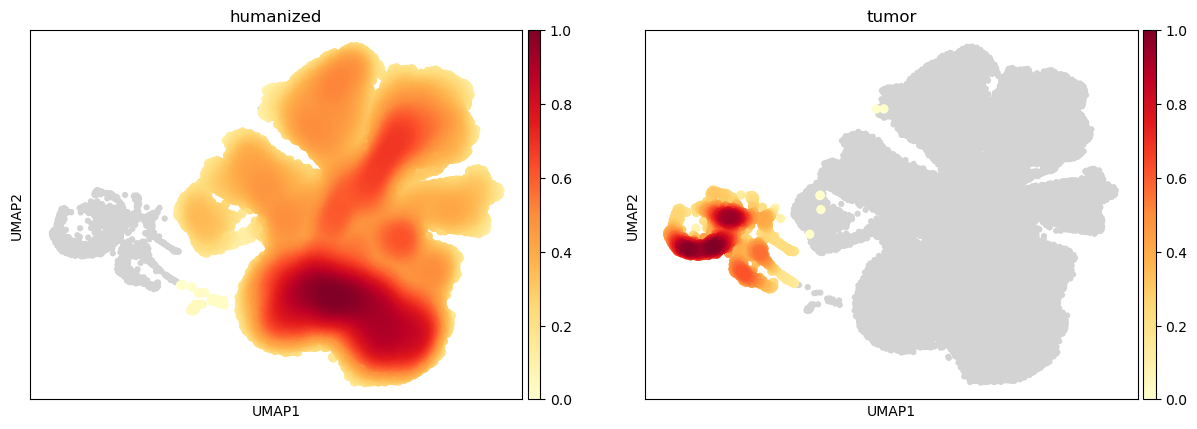

In [ ]:
sc.tl.embedding_density(embed, basis="umap", groupby="species")
sc.pl.embedding_density(embed, basis="umap", groupby="species")

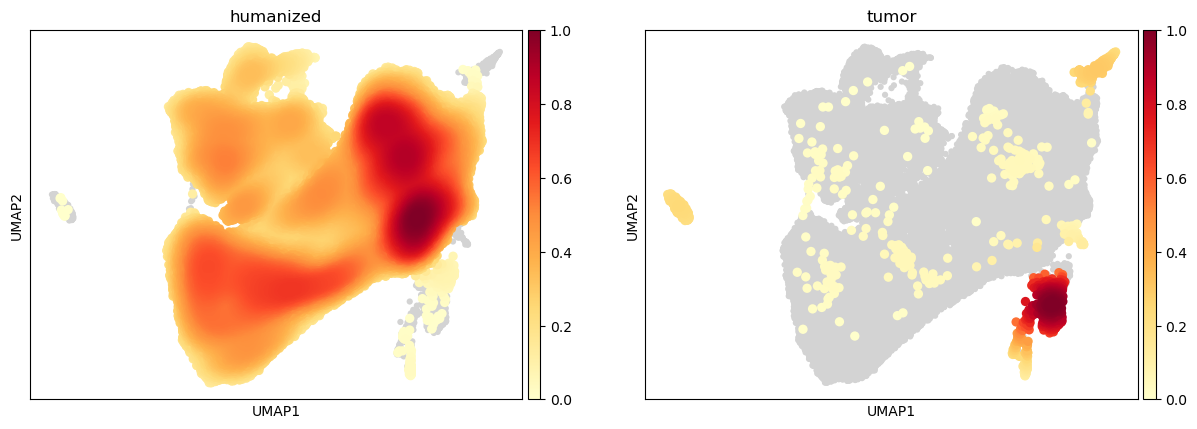

In [ ]:
sc.tl.embedding_density(merged, basis="umap", groupby="species")
sc.pl.embedding_density(merged, basis="umap", groupby="species")

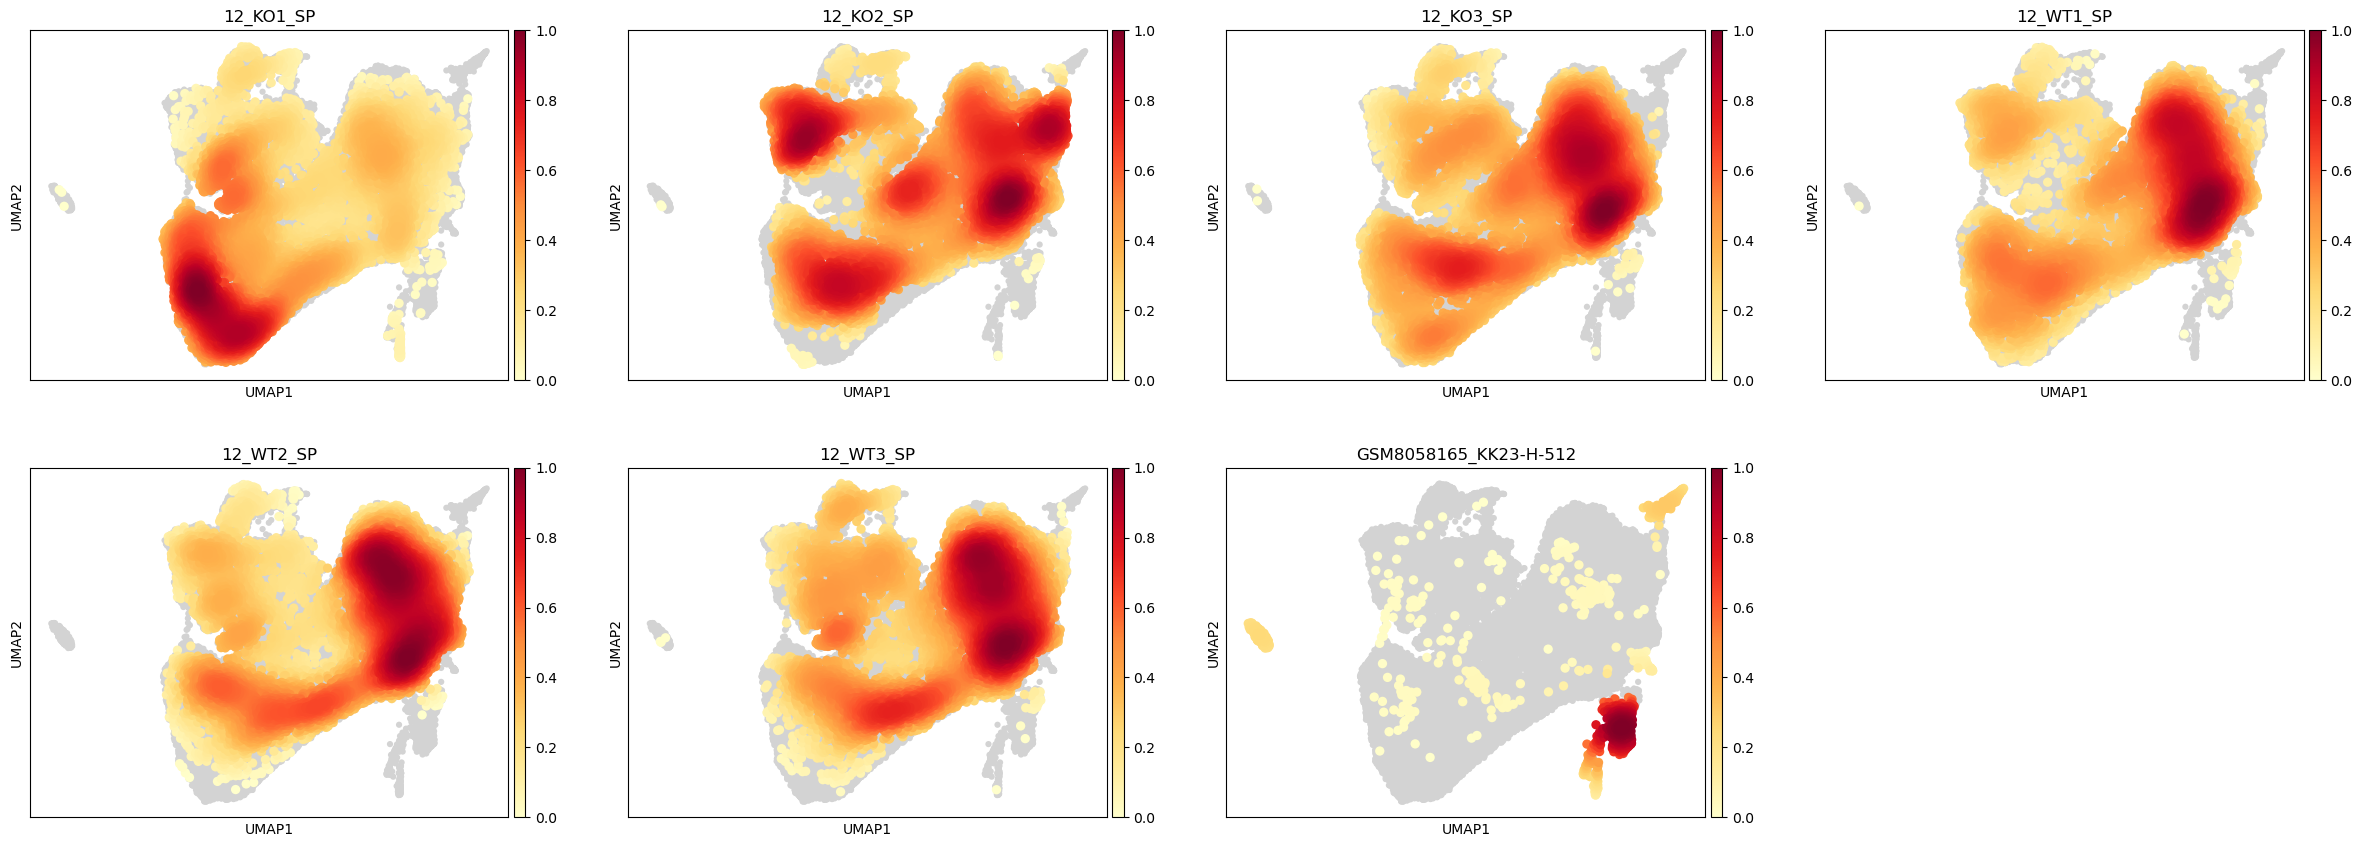

In [ ]:
sc.tl.embedding_density(merged, basis="umap", groupby="sample_origin")
sc.pl.embedding_density(merged, basis="umap", groupby="sample_origin")


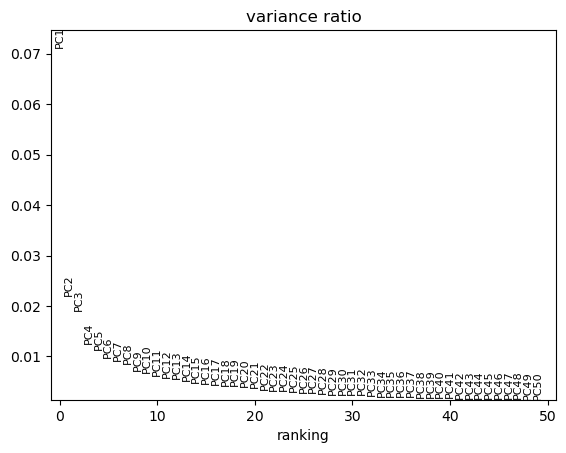

2026-03-02 17:44:42,360 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...
2026-03-02 17:44:53,485 - harmonypy - INFO - sklearn.KMeans initialization complete.
2026-03-02 17:44:53,766 - harmonypy - INFO - Iteration 1 of 10
2026-03-02 17:45:14,309 - harmonypy - INFO - Iteration 2 of 10
2026-03-02 17:45:34,787 - harmonypy - INFO - Iteration 3 of 10
2026-03-02 17:45:55,401 - harmonypy - INFO - Iteration 4 of 10
2026-03-02 17:46:16,025 - harmonypy - INFO - Iteration 5 of 10
2026-03-02 17:46:36,633 - harmonypy - INFO - Iteration 6 of 10
2026-03-02 17:46:57,250 - harmonypy - INFO - Iteration 7 of 10
2026-03-02 17:47:17,133 - harmonypy - INFO - Converged after 7 iterations


In [ ]:
# sc.pp.regress_out(merged, ["species"], n_jobs=1)

merged.layers["scale.data"] = merged.X.copy()
sc.pp.scale(merged, layer="scale.data") 

sc.pp.pca(merged, use_highly_variable=True,  n_comps=50, layer="scale.data")
sc.pl.pca_variance_ratio(merged, n_pcs=50, log=False)       

sc.external.pp.harmony_integrate(merged, key="sample_origin")

sc.pp.neighbors(
                merged,
                n_neighbors=pc_parameters["n_neighbors"],
                n_pcs=pc_parameters["n_pcs"],
                use_rep="X_pca_harmony"
            ) #compute the neighborhood graph of cells using the specified number of neighbors and PCs, which will be used for UMAP and Leiden clustering

            # UMAP
sc.tl.umap(
                merged
            )

            # Leiden
sc.tl.leiden(
                merged,
                resolution=pc_parameters["leiden_resolution"]
            )



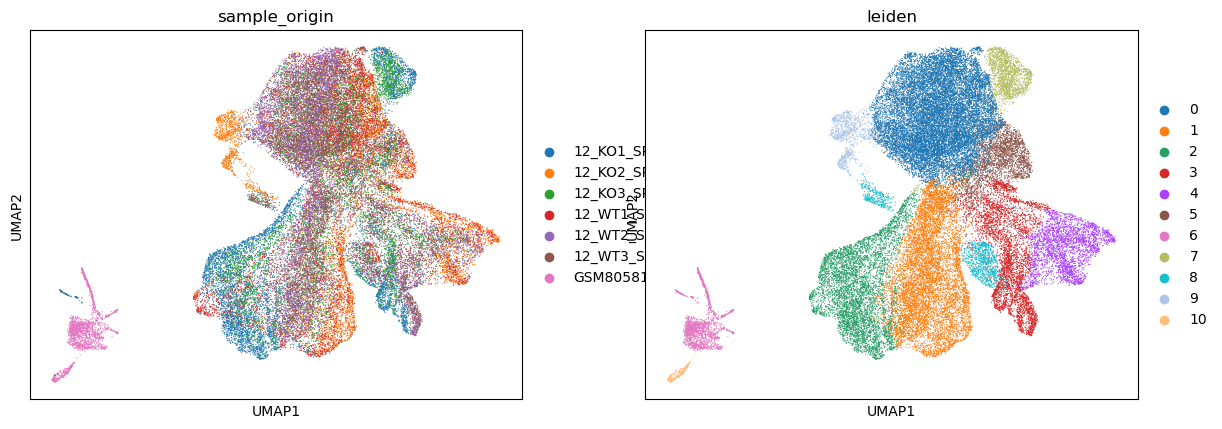

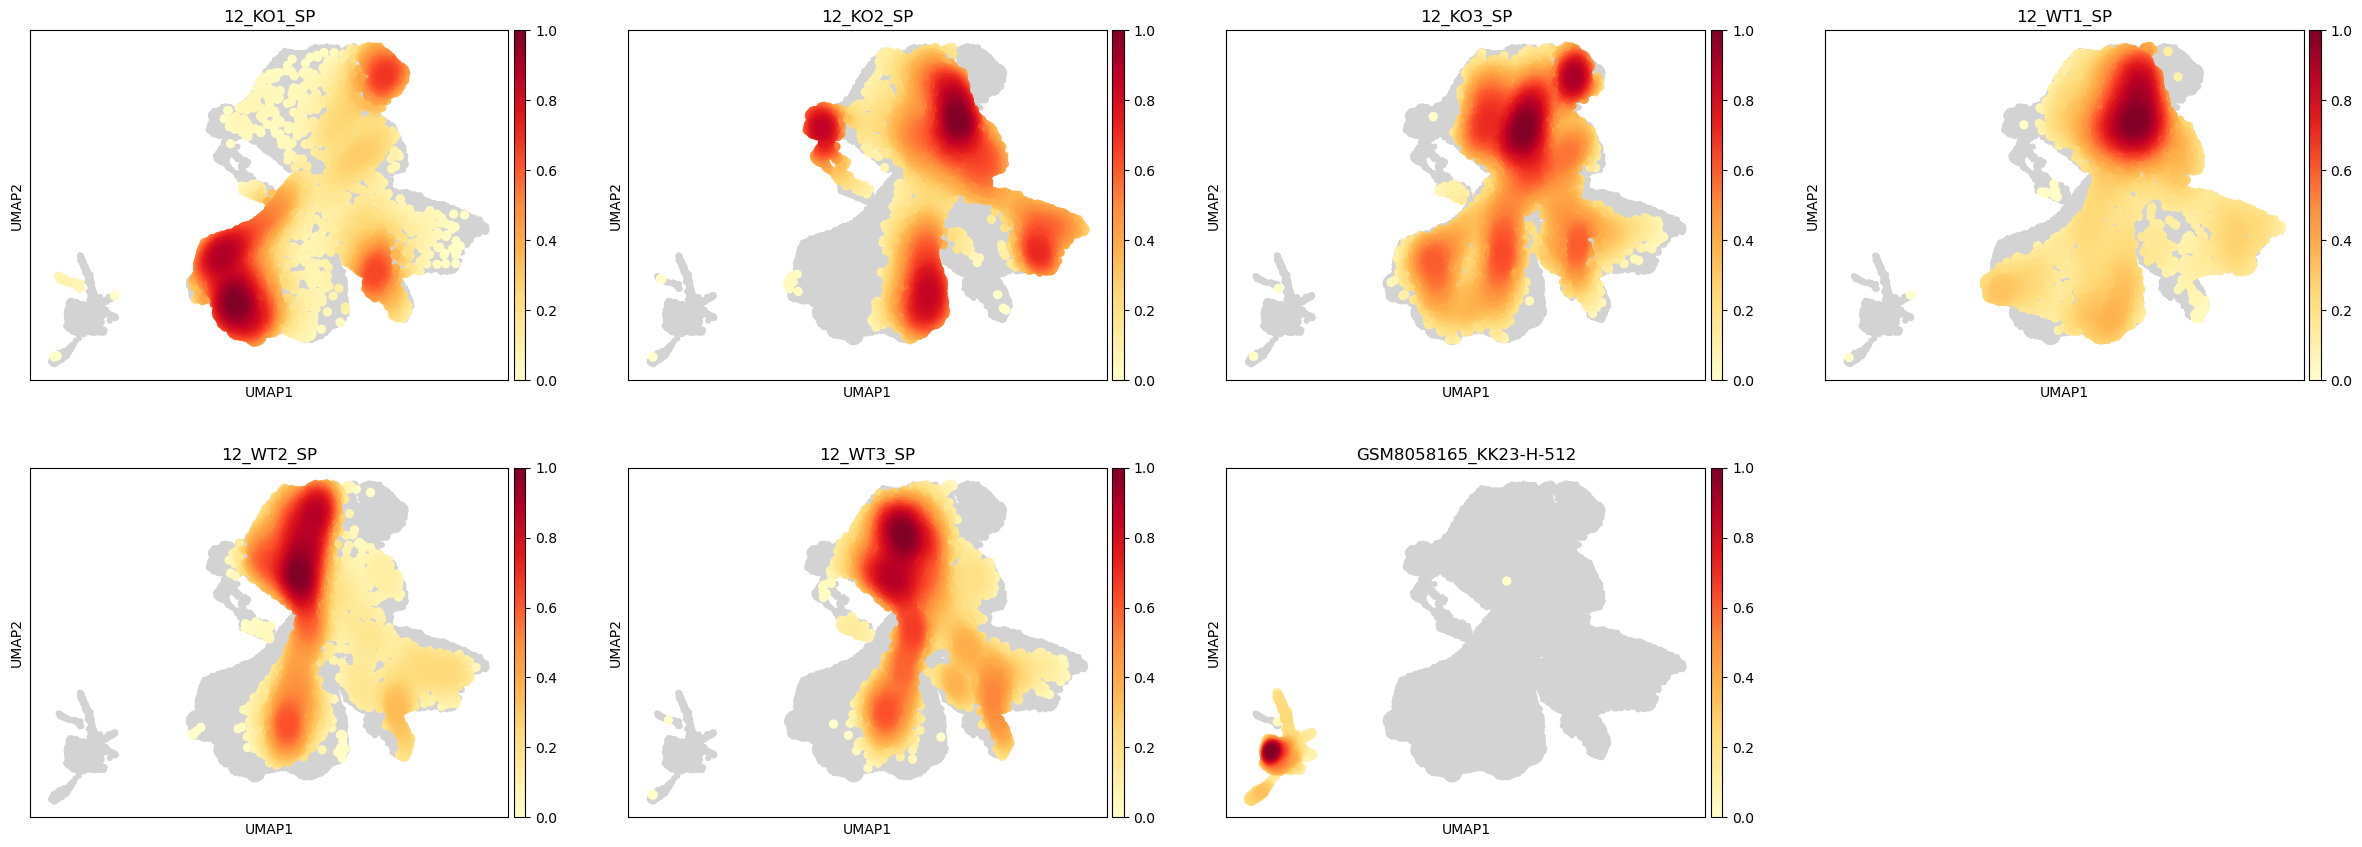

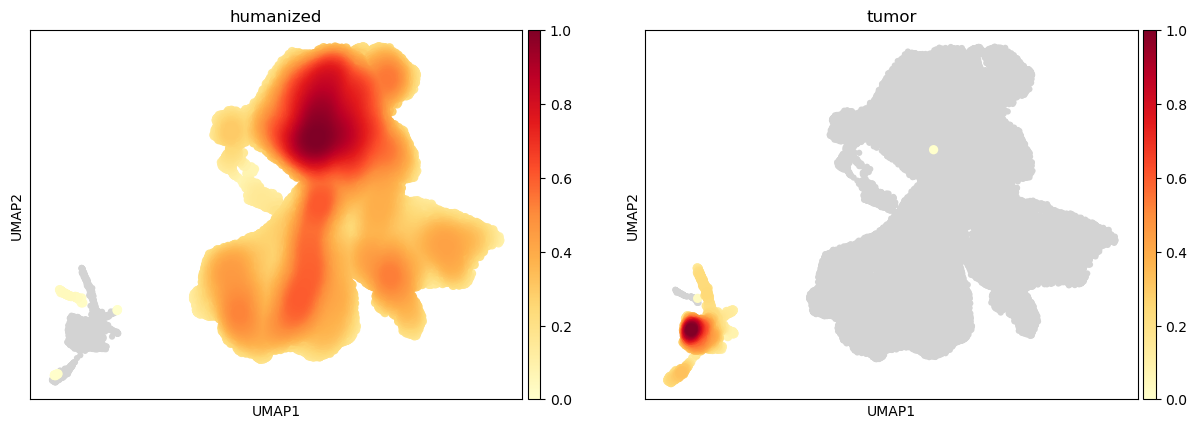

In [16]:
sc.pl.umap(merged, color=["sample_origin", "leiden"])

sc.tl.embedding_density(merged, basis="umap", groupby="sample_origin")
sc.pl.embedding_density(merged, basis="umap", groupby="sample_origin")
sc.tl.embedding_density(merged, basis="umap", groupby="species")
sc.pl.embedding_density(merged, basis="umap", groupby="species")

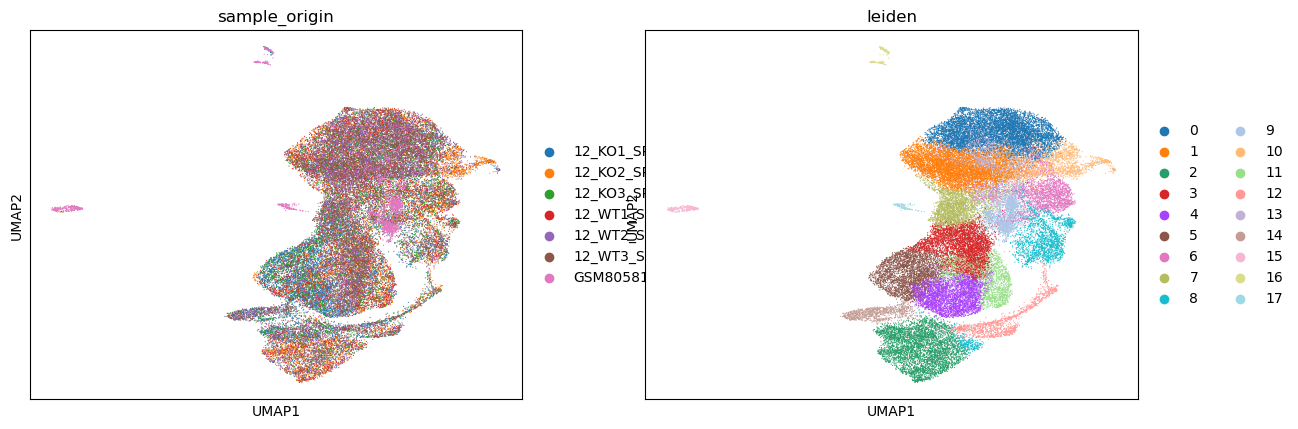

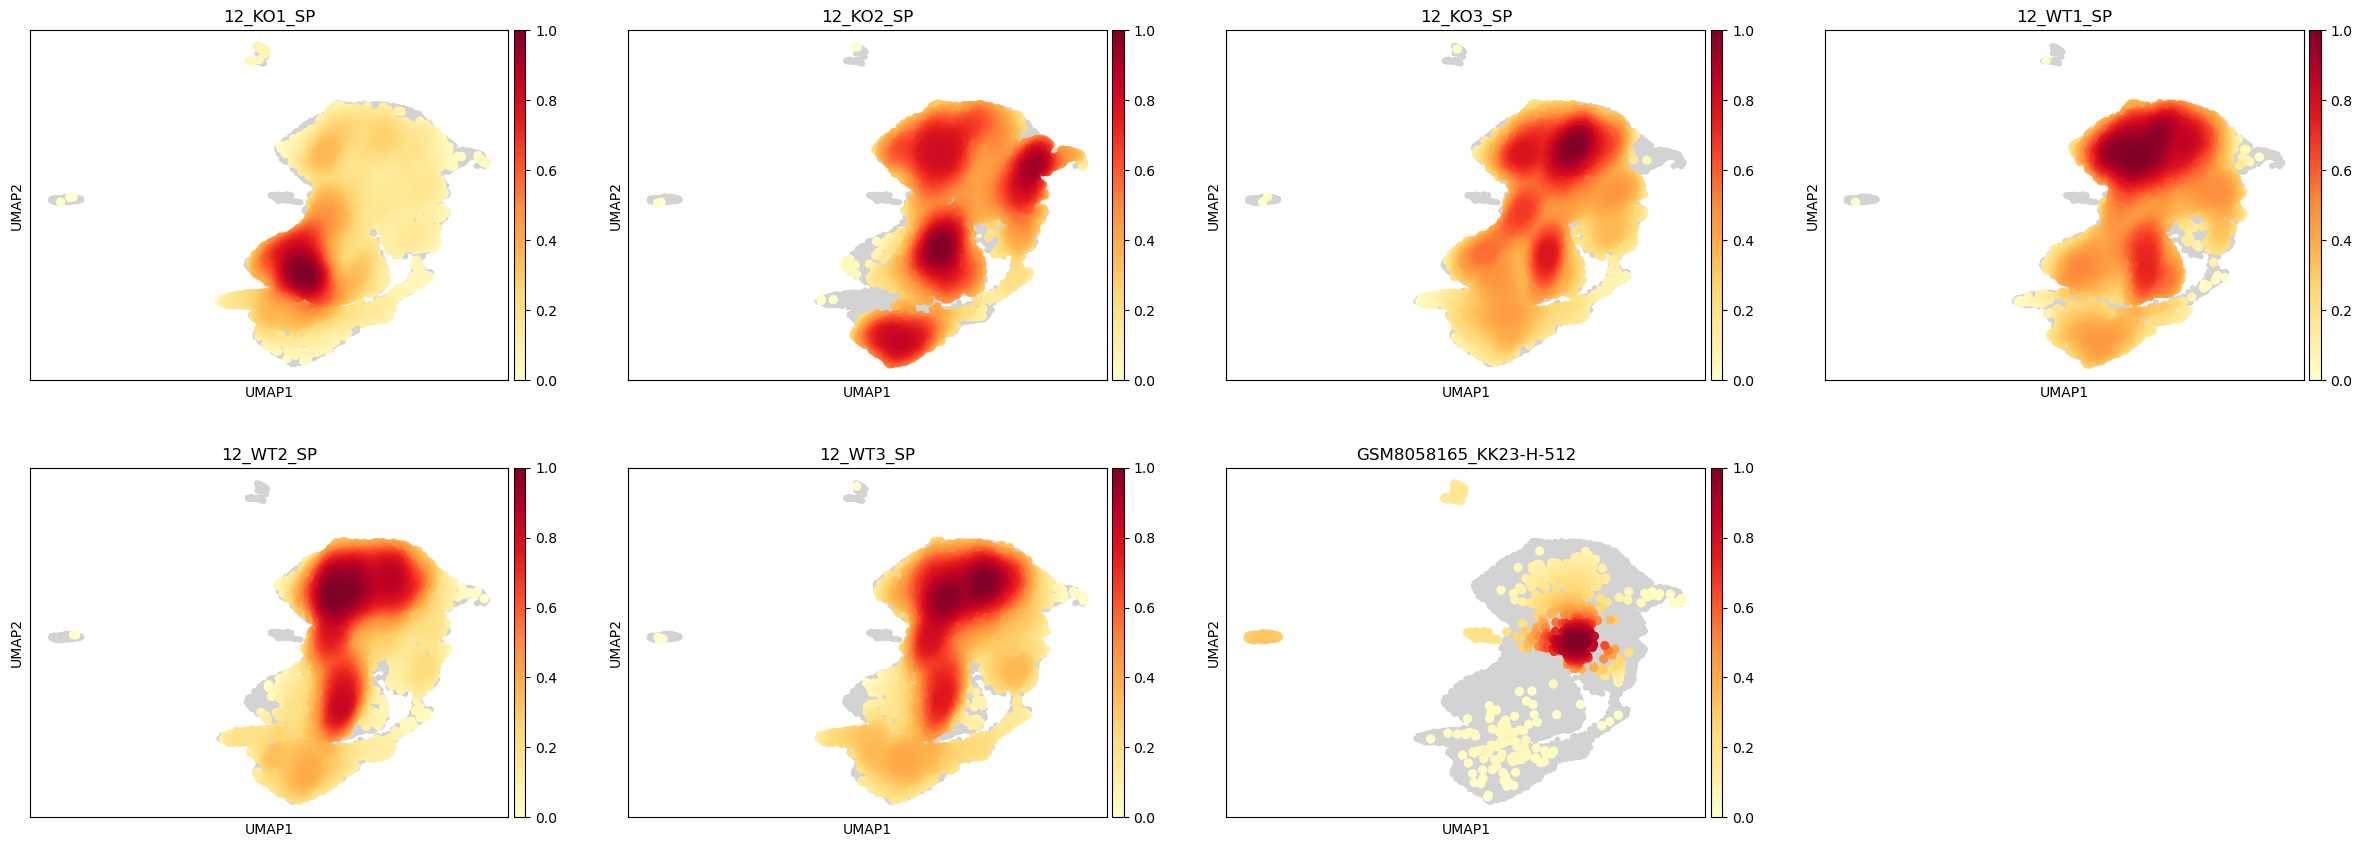

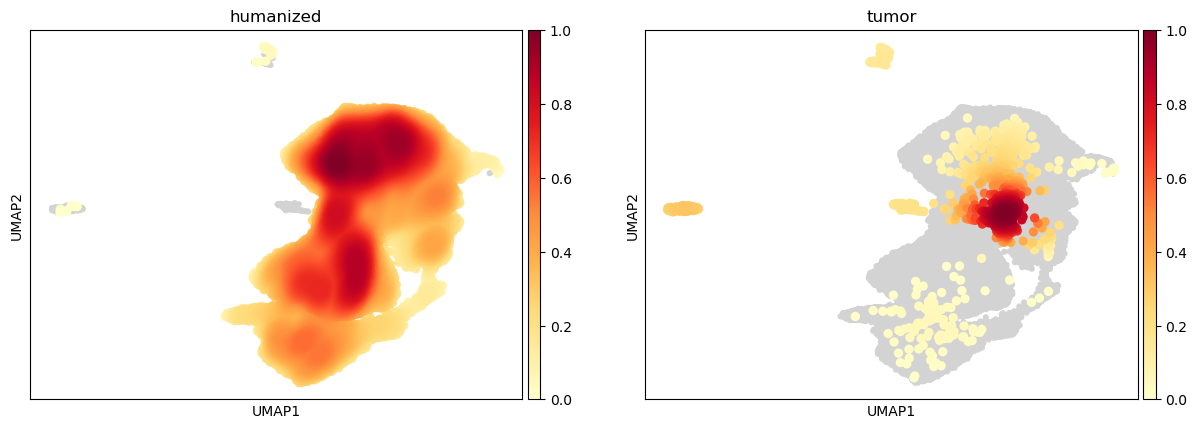

In [ ]:
sc.pl.umap(merged, color=["sample_origin", "leiden"])

sc.tl.embedding_density(merged, basis="umap", groupby="sample_origin")
sc.pl.embedding_density(merged, basis="umap", groupby="sample_origin")
sc.tl.embedding_density(merged, basis="umap", groupby="species")
sc.pl.embedding_density(merged, basis="umap", groupby="species")

In [30]:
merged = sc.read_h5ad("/home/sofia/Projects/etmr/defaria/snRNA/data/processed/merged/combined_GSM8058165_KK23-H-512.h5ad")
jessa = sc.read_h5ad("/home/sofia/Projects/etmr/defaria/scRNA/jessa/data/raw/so_etmr1_anotado.h5ad")

In [31]:
jessa.X[:5].toarray()

array([[0., 0., 0., ..., 1., 0., 0.],
       [0., 0., 0., ..., 4., 0., 6.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 1., 0., 0.],
       [0., 0., 0., ..., 1., 0., 0.]], shape=(5, 33950))

In [33]:
jessa.var

,names
WASH7P,WASH7P
RP11-34P13.7,RP11-34P13.7
CICP27,CICP27
AL627309.1,AL627309.1
RP11-34P13.13,RP11-34P13.13
...,...
AL354822.1,AL354822.1
PNRC2.1,PNRC2.1
SRSF10.1,SRSF10.1
CU459201.1,CU459201.1


In [34]:
gene_counts = pd.Series(jessa.var_names).value_counts()
problem_genes = gene_counts[gene_counts > 1]

print(problem_genes)

Series([], Name: count, dtype: int64)


In [35]:

jessa.raw = jessa.copy()

In [36]:
jessa.obs["sample_origin"] = "jessa"
jessa.obs["species"] = "tumor"

In [37]:
jessa

AnnData object with n_obs × n_vars = 6594 × 33950
    obs: 'nCount_RNA', 'nFeature_RNA', 'percent.mt', 'percent.ribo', 'nf', 'RNA_snn_res.0.8', 'seurat_clusters', 'cell_types_etmr1', 'cell_types_2_etmr1', 'S.Score', 'G2M.Score', 'Phase', 'cluster_cell_type', 'cluster_cell_type_phase', 'cluster_cell_type_condition', 'sample_origin', 'species'
    var: 'names'
    obsm: 'X_pca', 'X_umap.unintegrated'

In [40]:
jessa.obs = jessa.obs.filter(['sample_origin',
       'species'])

In [41]:
del jessa.uns
del jessa.obsm

In [42]:
jessa

AnnData object with n_obs × n_vars = 6594 × 33950
    obs: 'sample_origin', 'species'
    var: 'names'

In [44]:
jessa.layers["counts"] = jessa.X.copy()

In [45]:
jessa

AnnData object with n_obs × n_vars = 6594 × 33950
    obs: 'sample_origin', 'species'
    var: 'names'
    layers: 'counts'

In [46]:
import functions

In [47]:
jessa = functions.filter_anndata(jessa, "/home/sofia/Projects/etmr/defaria/scRNA/jessa/jessa/data/processed/jessa_all.h5ad")
jessa = functions.preprocess_adata(jessa)

In [48]:
jessa.write_h5ad("/home/sofia/Projects/etmr/defaria/scRNA/jessa/data/processed/jessa_pp.h5ad")

In [49]:
jessa

AnnData object with n_obs × n_vars = 6594 × 33950
    obs: 'sample_origin', 'species', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'pct_counts_ribo'
    var: 'names', 'mt', 'ribo', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm', 'mean', 'std'
    uns: 'filters', 'hvg', 'log1p'
    layers: 'counts', 'scale.data'

In [56]:
jessa.obs.describe()

,n_genes_by_counts,total_counts,total_counts_mt,pct_counts_mt,total_counts_ribo,pct_counts_ribo
count,6594.000000,6594.000000,6594.000000,6594.000000,6594.000000,6594.000000
mean,3364.989384,9308.176676,147.803003,1.732677,1989.042311,19.354413
std,1309.824534,5290.733376,99.461353,1.248787,1472.618333,7.697110
min,264.000000,498.000000,0.000000,0.000000,6.000000,0.370943
25%,2526.250000,5301.000000,72.000000,1.099713,793.000000,14.299104
50%,3436.000000,8694.500000,131.000000,1.448448,1685.000000,20.076285
75%,4320.000000,12858.250000,206.000000,1.890083,3070.000000,25.055537
max,5995.000000,27314.000000,742.000000,9.926238,9721.000000,69.536962


In [53]:
print("merged var unique:", merged.var_names.is_unique)
print("jessa var unique:", jessa.var_names.is_unique)

merged var unique: True
jessa var unique: True


In [70]:
import anndata as ad

common_genes = merged.var_names.intersection(jessa.var_names)

merged_filtered = merged[:, common_genes].copy()
jessa_filtered = jessa[:, common_genes].copy()


combined_adata = ad.concat(
    [merged_filtered, jessa_filtered],
    label="other",
    keys=["a", "b"]
)


In [71]:
gene_counts = pd.Series(combined_adata.var_names).value_counts()
problem_genes = gene_counts[gene_counts > 1]

print(problem_genes)

Series([], Name: count, dtype: int64)


In [72]:
del combined_adata.obs["other"]
combined_adata.obs

,sample_origin,n_genes_by_counts,total_counts,total_counts_mt,pct_counts_mt,total_counts_ribo,pct_counts_ribo,species
12_KO1_SP_AAACCCAAGACGCAGT-1-KO,12_KO1_SP,4438,14857.0,67.0,0.450966,609.0,4.099078,humanized
12_KO1_SP_AAACCCAAGGTCACCC-1-KO,12_KO1_SP,4189,12223.0,47.0,0.384521,201.0,1.644441,humanized
12_KO1_SP_AAACCCAAGGTCTACT-1-KO,12_KO1_SP,6109,26033.0,51.0,0.195905,515.0,1.978258,humanized
12_KO1_SP_AAACCCACAAAGACGC-1-KO,12_KO1_SP,5792,23484.0,76.0,0.323625,1724.0,7.341168,humanized
12_KO1_SP_AAACCCACAATTCTTC-1-KO,12_KO1_SP,5107,19465.0,79.0,0.405857,476.0,2.445415,humanized
...,...,...,...,...,...,...,...,...
TTTGTCAAGTGTCCCG-1,jessa,597,785.0,10.0,1.273885,156.0,19.872611,tumor
TTTGTCAGTAAAGGAG-1,jessa,4276,11668.0,191.0,1.636956,2048.0,17.552280,tumor
TTTGTCAGTACAGCAG-1,jessa,5088,13155.0,224.0,1.702775,1229.0,9.342455,tumor
TTTGTCATCAATCTCT-1,jessa,531,605.0,8.0,1.322314,62.0,10.247934,tumor


In [73]:
combined_adata = functions.preprocess_adata(combined_adata)

In [74]:
combined_adata.raw

In [ ]:
combined_adata

AnnData object with n_obs × n_vars = 51635 × 14037
    obs: 'sample_origin', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'pct_counts_ribo', 'species'
    var: 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm', 'mean', 'std'
    uns: 'hvg', 'log1p'
    layers: 'counts', 'scale.data'

In [78]:
sc.pp.pca(combined_adata)

In [80]:
sc.external.pp.harmony_integrate(combined_adata, key="species")

2026-02-27 17:48:46,173 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...
2026-02-27 17:49:03,795 - harmonypy - INFO - sklearn.KMeans initialization complete.
2026-02-27 17:49:04,209 - harmonypy - INFO - Iteration 1 of 10
2026-02-27 17:49:31,993 - harmonypy - INFO - Iteration 2 of 10
2026-02-27 17:49:55,494 - harmonypy - INFO - Converged after 2 iterations


In [82]:
sc.pp.neighbors(
                combined_adata,
                n_neighbors=pc_parameters["n_neighbors"],
                n_pcs=pc_parameters["n_pcs"],
                use_rep="X_pca_harmony"
            ) #compute the neighborhood graph of cells using the specified number of neighbors and PCs, which will be used for UMAP and Leiden clustering

            # UMAP
sc.tl.umap(
                combined_adata
            )

            # Leiden
sc.tl.leiden(
                combined_adata,
                resolution=pc_parameters["leiden_resolution"]
            )

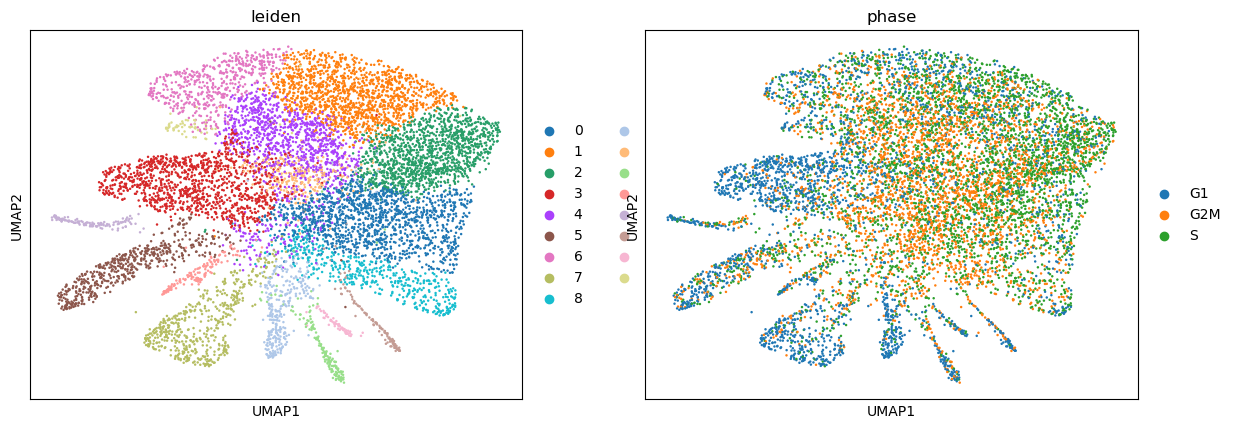

In [ ]:
sc.pl.embedding(adata, basis="umap", color=["leiden", "phase"])

In [85]:
combined_adata = combined_adata.raw.to_adata().copy()

In [89]:
combined_adata.obs["sample_origin"]

12_KO1_SP_AAACCCAAGACGCAGT-1-KO    12_KO1_SP
12_KO1_SP_AAACCCAAGGTCACCC-1-KO    12_KO1_SP
12_KO1_SP_AAACCCAAGGTCTACT-1-KO    12_KO1_SP
12_KO1_SP_AAACCCACAAAGACGC-1-KO    12_KO1_SP
12_KO1_SP_AAACCCACAATTCTTC-1-KO    12_KO1_SP
                                     ...    
TTTGTCAAGTGTCCCG-1                     jessa
TTTGTCAGTAAAGGAG-1                     jessa
TTTGTCAGTACAGCAG-1                     jessa
TTTGTCATCAATCTCT-1                     jessa
TTTGTCATCTTAACCT-1                     jessa
Name: sample_origin, Length: 51635, dtype: category
Categories (8, object): ['12_KO1_SP', '12_KO2_SP', '12_KO3_SP', '12_WT1_SP', '12_WT2_SP', '12_WT3_SP', 'GSM8058165_KK23-H-512', 'jessa']

In [90]:

base = "GSM8058165_KK23-H-512"
lst = [base]

combined_adata.obs["platform"] = combined_adata.obs["sample_origin"].isin(lst).map({
    True: "snRNA",
    False: "scRNA"
})

In [92]:
sc.external.pp.harmony_integrate(combined_adata, key="platform")

2026-02-27 18:36:36,082 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...
2026-02-27 18:36:54,296 - harmonypy - INFO - sklearn.KMeans initialization complete.
2026-02-27 18:36:55,222 - harmonypy - INFO - Iteration 1 of 10
2026-02-27 18:37:42,297 - harmonypy - INFO - Iteration 2 of 10
2026-02-27 18:38:26,213 - harmonypy - INFO - Converged after 2 iterations


In [93]:
sc.pp.neighbors(
                combined_adata,
                n_neighbors=pc_parameters["n_neighbors"],
                n_pcs=pc_parameters["n_pcs"],
                use_rep="X_pca_harmony"
            ) #compute the neighborhood graph of cells using the specified number of neighbors and PCs, which will be used for UMAP and Leiden clustering

            # UMAP
sc.tl.umap(
                combined_adata
            )

            # Leiden
sc.tl.leiden(
                combined_adata,
                resolution=pc_parameters["leiden_resolution"]
            )

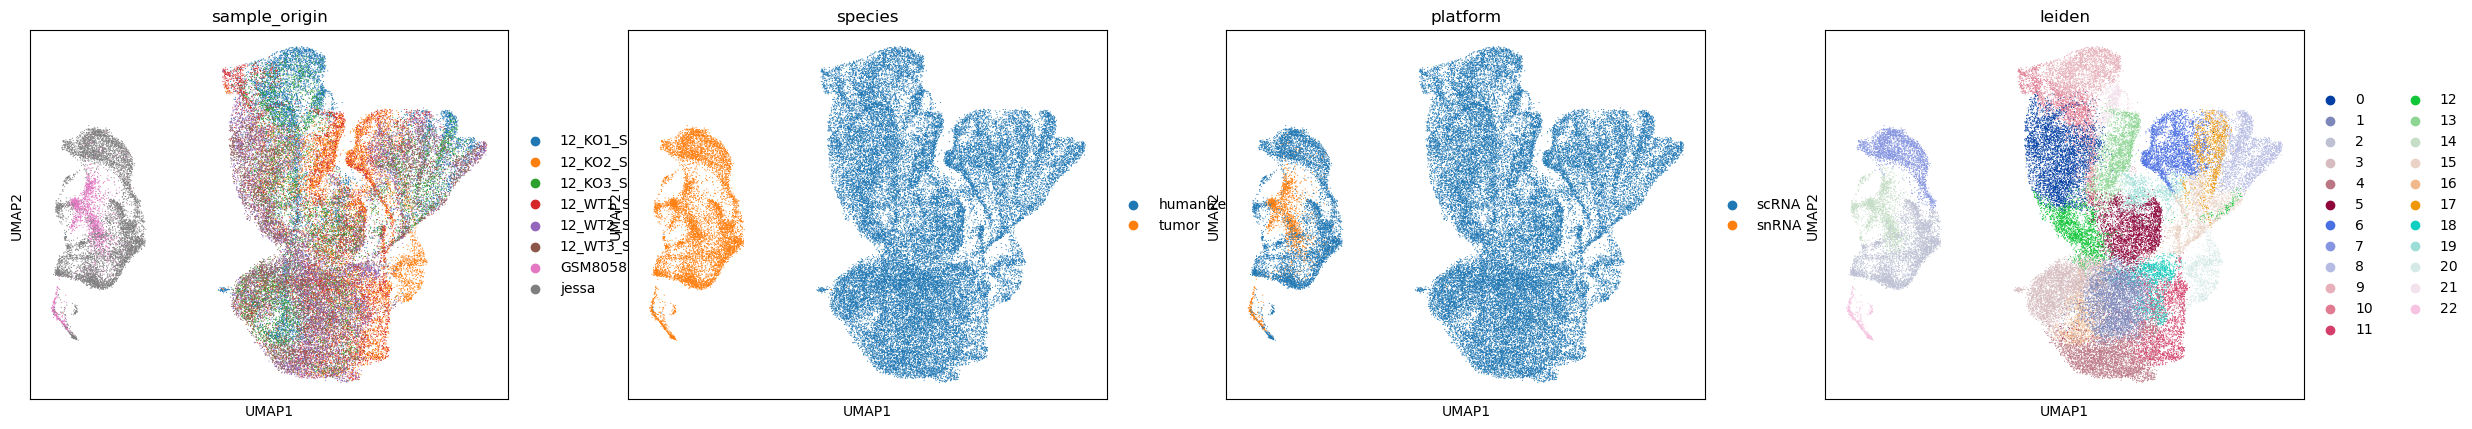

In [94]:
sc.pl.embedding(combined_adata, basis="umap", color=["sample_origin", "species", "platform","leiden"])